## Forecasting setup

The target series is built before splitting it chronologically: the first 110 observations are used for development and the last 24 are reserved for the two-hour forecast. Candidate selection uses rolling validation within the development window; the final segment is only a retrospective comparison.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src" / "models.py").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Could not find src/models.py. "
            "Make sure this notebook is inside the atomity project."
        )
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data import load_data
from targets import build_aggregate_targets
from models import MODEL_REGISTRY
from experiments import FOLDS, HORIZON, calculate_metrics

DATA_DIR = PROJECT_ROOT / "data" / "raw"

cpu_readings, vm_metadata = load_data(DATA_DIR)
aggregate = build_aggregate_targets(cpu_readings)

development = aggregate.iloc[:110].copy()
holdout = aggregate.iloc[110:].copy()

development_cpu = development[
    "aggregate_cpu_utilization"
].to_numpy(dtype=float)

assert len(development) == 110
assert len(holdout) == 24
assert len(MODEL_REGISTRY) == 8

print(f"Project root: {PROJECT_ROOT}")
print(f"Source directory: {SRC_DIR}")
print(f"CPU readings: {cpu_readings.shape}")
print(f"Aggregate series: {aggregate.shape}")
print(f"Development observations: {len(development)}")
print(f"Reserved holdout observations: {len(holdout)}")
print(f"Registered models: {len(MODEL_REGISTRY)}")

Project root: c:\Users\User\projects\atomity
Source directory: c:\Users\User\projects\atomity\src
CPU readings: (1340000, 5)
Aggregate series: (134, 3)
Development observations: 110
Reserved holdout observations: 24
Registered models: 8


In [2]:
import numpy as np
import pandas as pd

required_columns = {
    "timestamp",
    "active_vm_count",
    "aggregate_cpu_utilization",
}

assert required_columns.issubset(aggregate.columns)
assert len(aggregate) == 134
assert len(development) == 110
assert len(holdout) == 24

assert aggregate["timestamp"].is_monotonic_increasing
assert aggregate["timestamp"].is_unique

assert aggregate["active_vm_count"].notna().all()
assert aggregate["aggregate_cpu_utilization"].notna().all()

assert (
    aggregate["aggregate_cpu_utilization"].between(0, 100).all()
)

assert np.isfinite(
    aggregate["aggregate_cpu_utilization"].to_numpy(dtype=float)
).all()

assert development.index.max() < holdout.index.min()

print("Forecasting setup verified.")
print(f"Development period: {len(development)} observations")
print(f"Holdout period:     {len(holdout)} observations")
print(
    "Development CPU range: "
    f"{development['aggregate_cpu_utilization'].min():.4f}–"
    f"{development['aggregate_cpu_utilization'].max():.4f}"
)

Forecasting setup verified.
Development period: 110 observations
Holdout period:     24 observations
Development CPU range: 9.1116–9.9122


## Define the search space

Each candidate is evaluated on the same chronological folds. The final 24 observations are not used to tune these configurations; later comparisons on that period are retrospective only.

In [3]:
from itertools import product

# Every entry is one model configuration.
CONFIGS = []

# 1. Moving-average baselines
for window in [3, 6, 12, 18]:
    CONFIGS.append({
        "family": "Moving Average",
        "params": {"window": window},
    })

# 2. Simple exponential smoothing
# Fixed smoothing levels are tested alongside the optimized fit.
for alpha in [0.2, 0.5, 0.8, None]:
    CONFIGS.append({
        "family": "SES",
        "params": {"smoothing_level": alpha},
    })

# 3. Holt trend models
for damped in [False, True]:
    CONFIGS.append({
        "family": "Holt",
        "params": {"damped_trend": damped},
    })

# 4. ARIMA: intentionally small search space.
for order in [
    (1, 0, 0),
    (0, 0, 1),
    (1, 0, 1),
    (2, 0, 0),
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
]:
    CONFIGS.append({
        "family": "ARIMA",
        "params": {"order": order},
    })

# 5. Ridge lag regression
for alpha in [1, 10, 30, 75, 150, 300]:
    CONFIGS.append({
        "family": "Ridge",
        "params": {"alpha": alpha},
    })

# 6. Random Forest: regularized configurations
for depth, leaf, max_features in product(
    [2, 4],
    [5, 10],
    [0.7, 1.0],
):
    CONFIGS.append({
        "family": "Random Forest",
        "params": {
            "max_depth": depth,
            "min_samples_leaf": leaf,
            "max_features": max_features,
        },
    })

print(f"Total configurations: {len(CONFIGS)}")

config_table = pd.DataFrame([
    {
        "family": config["family"],
        **config["params"],
    }
    for config in CONFIGS
])

display(config_table)

Total configurations: 31


,family,window,smoothing_level,damped_trend,order,alpha,max_depth,min_samples_leaf,max_features
0,Moving Average,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Moving Average,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Moving Average,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Moving Average,18.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,SES,NaN,0.2,NaN,NaN,NaN,NaN,NaN,NaN
5,SES,NaN,0.5,NaN,NaN,NaN,NaN,NaN,NaN
6,SES,NaN,0.8,NaN,NaN,NaN,NaN,NaN,NaN
7,SES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Holt,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN
9,Holt,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN


In [4]:
def validate_forecast_inputs(history, horizon):
    history = np.asarray(history, dtype=float).reshape(-1)

    if len(history) == 0:
        raise ValueError("History must not be empty.")

    if not np.isfinite(history).all():
        raise ValueError("History contains non-finite values.")

    if not isinstance(horizon, (int, np.integer)) or horizon <= 0:
        raise ValueError("Horizon must be a positive integer.")

    return history


def validate_forecast(prediction, horizon):
    prediction = np.asarray(prediction, dtype=float).reshape(-1)

    if len(prediction) != horizon:
        raise ValueError(
            f"Expected {horizon} predictions, got {len(prediction)}."
        )

    if not np.isfinite(prediction).all():
        raise ValueError("Forecast contains non-finite values.")

    return prediction


def forecast_moving_average(history, horizon, window):
    history = validate_forecast_inputs(history, horizon)

    if not isinstance(window, (int, np.integer)) or window <= 0:
        raise ValueError("Window must be a positive integer.")

    level = float(np.mean(history[-window:]))
    prediction = np.full(horizon, level, dtype=float)

    return validate_forecast(prediction, horizon)


def forecast_persistence(history, horizon):
    history = validate_forecast_inputs(history, horizon)

    prediction = np.full(horizon, history[-1], dtype=float)

    return validate_forecast(prediction, horizon)


def forecast_lag_regression(history, horizon, model, lags=12):
    history = validate_forecast_inputs(history, horizon)

    if len(history) <= lags:
        raise ValueError(
            f"Need more than {lags} historical observations; "
            f"received {len(history)}."
        )

    X = np.array([
        history[i - lags:i]
        for i in range(lags, len(history))
    ])
    y = history[lags:]

    model.fit(X, y)

    rolling_history = list(history)
    predictions = []

    for _ in range(horizon):
        features = np.asarray(
            rolling_history[-lags:], dtype=float
        ).reshape(1, -1)

        prediction = float(model.predict(features)[0])
        predictions.append(prediction)
        rolling_history.append(prediction)

    return validate_forecast(predictions, horizon)


def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)

    if len(actual) != len(predicted):
        raise ValueError("Actual and predicted lengths differ.")

    errors = predicted - actual

    return {
        "MAE": float(np.mean(np.abs(errors))),
        "RMSE": float(np.sqrt(np.mean(errors**2))),
        "Mean Bias": float(np.mean(errors)),
    }


print("Forecast helper functions defined.")

Forecast helper functions defined.


In [5]:
import warnings

from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor


def forecast_config(history, horizon, config):
    history = validate_forecast_inputs(history, horizon)

    family = config["family"]
    params = config["params"]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        if family == "Moving Average":
            return forecast_moving_average(
                history,
                horizon,
                window=params["window"],
            )

        elif family == "SES":
            alpha = params["smoothing_level"]

            if alpha is None:
                fitted = SimpleExpSmoothing(
                    history,
                    initialization_method="estimated",
                ).fit()
            else:
                fitted = SimpleExpSmoothing(
                    history,
                    initialization_method="estimated",
                ).fit(
                    smoothing_level=alpha,
                    optimized=False,
                )

            prediction = fitted.forecast(horizon)

        elif family == "Holt":
            fitted = Holt(
                history,
                damped_trend=params["damped_trend"],
                initialization_method="estimated",
            ).fit(optimized=True)

            prediction = fitted.forecast(horizon)

        elif family == "ARIMA":
            fitted = ARIMA(
                history,
                order=params["order"],
            ).fit()

            prediction = fitted.forecast(horizon)

        elif family == "Ridge":
            model = make_pipeline(
                StandardScaler(),
                Ridge(alpha=params["alpha"]),
            )

            prediction = forecast_lag_regression(
                history, horizon, model
            )

        elif family == "Random Forest":
            model = RandomForestRegressor(
                n_estimators=200,
                max_depth=params["max_depth"],
                min_samples_leaf=params["min_samples_leaf"],
                max_features=params["max_features"],
                random_state=42,
                n_jobs=-1,
            )

            prediction = forecast_lag_regression(
                history, horizon, model
            )

        else:
            raise ValueError(f"Unknown model family: {family}")

    return validate_forecast(prediction, horizon)


for config in CONFIGS:
    forecast = forecast_config(development_cpu[:50], HORIZON, config)
    assert forecast.shape == (HORIZON,), (
        f"Unexpected forecast shape for {config}: {forecast.shape}"
    )
    assert np.isfinite(forecast).all(), (
        f"Non-finite forecast for {config}"
    )

print(f"All {len(CONFIGS)} configurations passed the forecast smoke test.")

All 31 configurations passed the forecast smoke test.


## Rolling-origin search

For each fold, fit from the available history and predict the next 24 observations. The training window expands forward in time; no random shuffle is used.

In [6]:
search_rows = []
search_failures = []

for config_index, config in enumerate(CONFIGS, start=1):
    fold_metrics = []

    for fold_number, (train_end, validation_end) in enumerate(
        FOLDS, start=1
    ):
        history = development_cpu[:train_end]
        actual = development_cpu[train_end:validation_end]

        if len(history) == 0:
            raise ValueError(
                f"Fold {fold_number} has empty training history."
            )

        if len(actual) != HORIZON:
            raise ValueError(
                f"Fold {fold_number} has {len(actual)} validation "
                f"observations; expected {HORIZON}."
            )

        try:
            predicted = forecast_config(
                history=history,
                horizon=HORIZON,
                config=config,
            )

            metrics = regression_metrics(actual, predicted)

            fold_metrics.append({
                "fold": fold_number,
                **metrics,
            })

        except Exception as exc:
            search_failures.append({
                "family": config["family"],
                "params": repr(config["params"]),
                "fold": fold_number,
                "error": repr(exc),
            })

    # Keep a configuration only if it succeeds on every validation fold.
    if len(fold_metrics) == len(FOLDS):
        fold_df = pd.DataFrame(fold_metrics)

        search_rows.append({
            "family": config["family"],
            "params": config["params"],
            "Mean_MAE": fold_df["MAE"].mean(),
            "Mean_RMSE": fold_df["RMSE"].mean(),
            "Mean_Bias": fold_df["Mean Bias"].mean(),
            "MAE_Std": fold_df["MAE"].std(ddof=0),
            "Worst_Fold_MAE": fold_df["MAE"].max(),
        })

    if config_index % 5 == 0 or config_index == len(CONFIGS):
        print(
            f"Evaluated {config_index}/{len(CONFIGS)} configurations"
        )

search_results = pd.DataFrame(search_rows)

if not search_results.empty:
    search_results = search_results.sort_values(
        ["Mean_MAE", "Mean_RMSE"]
    ).reset_index(drop=True)

    print("\nTop 15 configurations:")
    display(search_results.head(15).round(5))
else:
    print("No configurations completed successfully on every fold.")
if search_failures:
    print(
        f"\nFailed configuration/fold evaluations: "
        f"{len(search_failures)}"
    )
    display(pd.DataFrame(search_failures))
else:
    print("\nNo configuration/fold failures.")

print("\nValidation summary")
print(f"Configurations attempted: {len(CONFIGS)}")
print(f"Configurations eligible: {len(search_results)}")
print(f"Validation folds: {len(FOLDS)}")
print(f"Forecast horizon: {HORIZON}")
print(f"Development observations: {len(development_cpu)}")

Evaluated 5/31 configurations
Evaluated 10/31 configurations
Evaluated 15/31 configurations
Evaluated 20/31 configurations
Evaluated 25/31 configurations
Evaluated 30/31 configurations
Evaluated 31/31 configurations

Top 15 configurations:


,family,params,Mean_MAE,Mean_RMSE,Mean_Bias,MAE_Std,Worst_Fold_MAE
0,ARIMA,"{'order': (2, 0, 0)}",0.19483,0.22458,0.01267,0.05874,0.30164
1,ARIMA,"{'order': (1, 0, 1)}",0.19729,0.22834,0.02954,0.06127,0.30211
2,ARIMA,"{'order': (1, 0, 0)}",0.19986,0.22884,0.01100,0.05591,0.30255
3,ARIMA,"{'order': (0, 0, 1)}",0.20613,0.23514,0.00997,0.05238,0.30252
4,Random Forest,"{'max_depth': 2, 'min_samples_leaf': 10, 'max_...",0.20737,0.23757,0.02035,0.09674,0.34152
5,Random Forest,"{'max_depth': 4, 'min_samples_leaf': 10, 'max_...",0.20817,0.23818,0.02084,0.09599,0.34152
6,Random Forest,"{'max_depth': 2, 'min_samples_leaf': 10, 'max_...",0.20920,0.23900,0.02383,0.09931,0.35024
7,Random Forest,"{'max_depth': 4, 'min_samples_leaf': 10, 'max_...",0.21017,0.23957,0.02472,0.09836,0.35024
8,ARIMA,"{'order': (1, 1, 0)}",0.21175,0.24685,0.10299,0.07971,0.29975
9,Ridge,{'alpha': 300},0.21253,0.24280,0.02374,0.05267,0.30838



No configuration/fold failures.

Validation summary
Configurations attempted: 31
Configurations eligible: 31
Validation folds: 7
Forecast horizon: 24
Development observations: 110


In [7]:
if search_results.empty:
    raise RuntimeError(
        "No configuration completed every validation fold."
    )

baseline_fold_metrics = []

for fold_number, (train_end, validation_end) in enumerate(
    FOLDS, start=1
):
    history = development_cpu[:train_end]
    actual = development_cpu[train_end:validation_end]

    if len(actual) != HORIZON:
        raise ValueError(
            f"Fold {fold_number}: expected {HORIZON} actual values, "
            f"got {len(actual)}."
        )

    predicted = forecast_persistence(history, HORIZON)
    metrics = regression_metrics(actual, predicted)

    baseline_fold_metrics.append({
        "fold": fold_number,
        **metrics,
    })

baseline_df = pd.DataFrame(baseline_fold_metrics)

baseline_mae = baseline_df["MAE"].mean()
baseline_rmse = baseline_df["RMSE"].mean()

ranked = search_results.copy()

ranked["MAE_Improvement_vs_Persistence_%"] = (
    100 * (baseline_mae - ranked["Mean_MAE"]) / baseline_mae
)

ranked["RMSE_Improvement_vs_Persistence_%"] = (
    100 * (baseline_rmse - ranked["Mean_RMSE"]) / baseline_rmse
)

print(f"Persistence mean MAE:  {baseline_mae:.5f}")
print(f"Persistence mean RMSE: {baseline_rmse:.5f}")

display(ranked.head(15).round(5))

Persistence mean MAE:  0.21524
Persistence mean RMSE: 0.25136


,family,params,Mean_MAE,Mean_RMSE,Mean_Bias,MAE_Std,Worst_Fold_MAE,MAE_Improvement_vs_Persistence_%,RMSE_Improvement_vs_Persistence_%
0,ARIMA,"{'order': (2, 0, 0)}",0.19483,0.22458,0.01267,0.05874,0.30164,9.48381,10.65588
1,ARIMA,"{'order': (1, 0, 1)}",0.19729,0.22834,0.02954,0.06127,0.30211,8.33970,9.16140
2,ARIMA,"{'order': (1, 0, 0)}",0.19986,0.22884,0.01100,0.05591,0.30255,7.14539,8.96073
3,ARIMA,"{'order': (0, 0, 1)}",0.20613,0.23514,0.00997,0.05238,0.30252,4.23229,6.45377
4,Random Forest,"{'max_depth': 2, 'min_samples_leaf': 10, 'max_...",0.20737,0.23757,0.02035,0.09674,0.34152,3.65852,5.48852
5,Random Forest,"{'max_depth': 4, 'min_samples_leaf': 10, 'max_...",0.20817,0.23818,0.02084,0.09599,0.34152,3.28725,5.24512
6,Random Forest,"{'max_depth': 2, 'min_samples_leaf': 10, 'max_...",0.20920,0.23900,0.02383,0.09931,0.35024,2.80729,4.91861
7,Random Forest,"{'max_depth': 4, 'min_samples_leaf': 10, 'max_...",0.21017,0.23957,0.02472,0.09836,0.35024,2.35655,4.69106
8,ARIMA,"{'order': (1, 1, 0)}",0.21175,0.24685,0.10299,0.07971,0.29975,1.62377,1.79657
9,Ridge,{'alpha': 300},0.21253,0.24280,0.02374,0.05267,0.30838,1.25880,3.40698


In [8]:
from statsmodels.tsa.forecasting.theta import ThetaModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings

In [9]:
extra_configs = []

# Expanded ARIMA grid
for order in [
    (0, 0, 0),
    (1, 0, 0),
    (0, 0, 1),
    (2, 0, 0),
    (0, 0, 2),
    (1, 0, 1),
    (2, 0, 1),
    (1, 0, 2),
    (2, 1, 0),
    (0, 1, 2),
    (1, 1, 1),
]:
    extra_configs.append({
        "name": f"ARIMA{order}",
        "family": "ARIMA",
        "params": {"order": order},
    })

# Theta method
extra_configs.append({
    "name": "Theta",
    "family": "Theta",
    "params": {},
})

# Small, exploratory SARIMA grid.
# These periods are sensitivity checks, NOT established seasonal cycles.
for period in [6, 12]:
    for order in [(1, 0, 0), (1, 0, 1)]:
        extra_configs.append({
            "name": f"SARIMA{order}x(1,0,0,{period})",
            "family": "SARIMA",
            "params": {
                "order": order,
                "seasonal_order": (1, 0, 0, period),
            },
        })


extra_rows = []
extra_failures = []

for config in extra_configs:
    fold_metrics = []

    for fold_number, (train_end, validation_end) in enumerate(FOLDS, start=1):
        history = development_cpu[:train_end]
        actual = development_cpu[train_end:validation_end]

        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                if config["family"] == "ARIMA":
                    fitted = ARIMA(
                        history,
                        order=config["params"]["order"]
                    ).fit()
                    predicted = np.asarray(
                        fitted.forecast(HORIZON), dtype=float
                    )

                elif config["family"] == "Theta":
                    fitted = ThetaModel(
                        history,
                        deseasonalize=False
                    ).fit()
                    predicted = np.asarray(
                        fitted.forecast(HORIZON), dtype=float
                    )

                elif config["family"] == "SARIMA":
                    fitted = SARIMAX(
                        history,
                        order=config["params"]["order"],
                        seasonal_order=config["params"]["seasonal_order"],
                        trend="c",
                        enforce_stationarity=False,
                        enforce_invertibility=False,
                    ).fit(disp=False, maxiter=200)

                    predicted = np.asarray(
                        fitted.forecast(HORIZON), dtype=float
                    )

            if predicted.shape != (HORIZON,) or not np.isfinite(predicted).all():
                raise ValueError("Forecast has invalid shape or non-finite values.")

            metrics = regression_metrics(actual, predicted)

            fold_metrics.append({
                "fold": fold_number,
                **metrics,
            })

        except Exception as exc:
            extra_failures.append({
                "model": config["name"],
                "fold": fold_number,
                "error": str(exc),
            })
            break

    if len(fold_metrics) == len(FOLDS):
        fold_df = pd.DataFrame(fold_metrics)

        extra_rows.append({
            "Model": config["name"],
            "Mean MAE": fold_df["MAE"].mean(),
            "Mean RMSE": fold_df["RMSE"].mean(),
            "Mean Bias": fold_df["Mean Bias"].mean(),
            "Successful Folds": len(fold_metrics),
        })


extra_results = pd.DataFrame(extra_rows)

if not extra_results.empty:
    extra_results = extra_results.sort_values(
        ["Mean MAE", "Mean RMSE"]
    ).reset_index(drop=True)

    display(extra_results.round(5))
else:
    print("No additional models completed all validation folds.")

if extra_failures:
    print(f"\nFailed model/fold runs: {len(extra_failures)}")
    display(pd.DataFrame(extra_failures))

,Model,Mean MAE,Mean RMSE,Mean Bias,Successful Folds
0,"ARIMA(2, 0, 0)",0.19483,0.22458,0.01267,7
1,"ARIMA(1, 0, 2)",0.19500,0.22613,0.02656,7
2,"ARIMA(2, 0, 1)",0.19628,0.22738,0.02845,7
3,"ARIMA(1, 0, 1)",0.19729,0.22834,0.02954,7
4,"ARIMA(1, 0, 0)",0.19986,0.22884,0.01100,7
5,"SARIMA(1, 0, 0)x(1,0,0,6)",0.20343,0.23132,0.03386,7
6,"ARIMA(0, 0, 2)",0.20500,0.23406,0.00916,7
7,"SARIMA(1, 0, 1)x(1,0,0,6)",0.20590,0.23501,0.04162,7
8,"ARIMA(0, 0, 1)",0.20613,0.23514,0.00997,7
9,"ARIMA(0, 0, 0)",0.20879,0.23843,0.00797,7


## Additional model checks

After the initial configuration search, this section checks a small set of ARIMA and seasonal sensitivity candidates. The seasonal periods are exploratory checks, not claims that this short trace has a proven repeating cycle.

## Business-Oriented Model Selection

In [10]:
if search_results.empty:
    raise RuntimeError("search_results is empty. Run the grid-search cells first.")

candidate_configs = [
    {
        "name": "ARIMA(2,0,0)",
        "family": "ARIMA",
        "params": {"order": (2, 0, 0)},
    },
    {
        "name": "ARIMA(1,0,2)",
        "family": "ARIMA",
        "params": {"order": (1, 0, 2)},
    },
]

for family in ["Random Forest", "Ridge"]:
    eligible = search_results[
        search_results["family"] == family
    ].sort_values(["Mean_MAE", "Mean_RMSE"])

    if eligible.empty:
        raise RuntimeError(f"No successful {family} configuration found.")

    best = eligible.iloc[0]

    candidate_configs.append({
        "name": f"Best {family}",
        "family": best["family"],
        "params": best["params"],
    })

candidate_configs.append({
    "name": "Persistence",
    "family": "Persistence",
    "params": {},
})

print("Candidates:")
for config in candidate_configs:
    print(f"- {config['name']}: {config['params']}")

Candidates:
- ARIMA(2,0,0): {'order': (2, 0, 0)}
- ARIMA(1,0,2): {'order': (1, 0, 2)}
- Best Random Forest: {'max_depth': 2, 'min_samples_leaf': 10, 'max_features': 0.7}
- Best Ridge: {'alpha': 300}
- Persistence: {}


## Compare operational errors

Summarize accuracy, signed bias, underforecast frequency, and peak errors across folds. Peak thresholds are computed from each fold?s training history so the validation values do not define their own threshold.

In [11]:
business_rows = []
fold_detail_rows = []
forecast_records = []

for config in candidate_configs:
    candidate_fold_rows = []
    all_peak_abs_errors = []
    all_peak_observations = 0

    for fold_number, (train_end, validation_end) in enumerate(FOLDS, start=1):
        history = development_cpu[:train_end]
        actual = development_cpu[train_end:validation_end]

        # Define peaks using training data only for this fold.
        fold_peak_threshold = float(np.quantile(history, 0.90))

        if config["family"] == "Persistence":
            predicted = forecast_persistence(history, HORIZON)
        else:
            predicted = forecast_config(history, HORIZON, config)

        errors = predicted - actual
        abs_errors = np.abs(errors)
        peak_mask = actual >= fold_peak_threshold

        peak_errors = abs_errors[peak_mask]
        all_peak_abs_errors.extend(peak_errors.tolist())
        all_peak_observations += int(peak_mask.sum())

        row = {
            "Model": config["name"],
            "Fold": fold_number,
            "Peak_Threshold": fold_peak_threshold,
            "MAE": float(np.mean(abs_errors)),
            "RMSE": float(np.sqrt(np.mean(errors ** 2))),
            "Bias": float(np.mean(errors)),
            "Underforecast_Rate": float(np.mean(errors < 0)),
            "Underforecast_MAE": (
                float(np.mean(np.abs(errors[errors < 0])))
                if np.any(errors < 0) else 0.0
            ),
            "Overforecast_MAE": (
                float(np.mean(errors[errors > 0]))
                if np.any(errors > 0) else 0.0
            ),
            "Peak_MAE": (
                float(np.mean(peak_errors))
                if len(peak_errors) else np.nan
            ),
            "Peak_Observations": int(peak_mask.sum()),
            "Forecast_Change": float(np.mean(np.abs(np.diff(predicted)))),
        }

        candidate_fold_rows.append(row)
        fold_detail_rows.append(row)

        forecast_records.append({
            "Model": config["name"],
            "Fold": fold_number,
            "Actual": actual.copy(),
            "Predicted": predicted.copy(),
        })

    fold_df = pd.DataFrame(candidate_fold_rows)

    business_rows.append({
        "Model": config["name"],
        "Mean_MAE": fold_df["MAE"].mean(),
        "Mean_RMSE": fold_df["RMSE"].mean(),
        "Mean_Bias": fold_df["Bias"].mean(),
        "MAE_Std_Between_Folds": fold_df["MAE"].std(ddof=0),
        "Worst_Fold_MAE": fold_df["MAE"].max(),
        "Underforecast_Rate": fold_df["Underforecast_Rate"].mean(),
        "Underforecast_MAE": fold_df["Underforecast_MAE"].mean(),
        "Overforecast_MAE": fold_df["Overforecast_MAE"].mean(),
        "Peak_MAE": (
            float(np.mean(all_peak_abs_errors))
            if all_peak_observations else np.nan
        ),
        "Peak_Observations": all_peak_observations,
        "Mean_Forecast_Change": fold_df["Forecast_Change"].mean(),
    })

business_results = (
    pd.DataFrame(business_rows)
    .sort_values(["Mean_MAE", "Mean_RMSE"])
    .reset_index(drop=True)
)

fold_details = pd.DataFrame(fold_detail_rows)

display(business_results.round(5))

,Model,Mean_MAE,Mean_RMSE,Mean_Bias,MAE_Std_Between_Folds,Worst_Fold_MAE,Underforecast_Rate,Underforecast_MAE,Overforecast_MAE,Peak_MAE,Peak_Observations,Mean_Forecast_Change
0,"ARIMA(2,0,0)",0.19483,0.22458,0.01267,0.05874,0.30164,0.35714,0.14908,0.14568,0.31367,45,0.00433
1,"ARIMA(1,0,2)",0.19500,0.22613,0.02656,0.06105,0.30172,0.36905,0.13168,0.15832,0.30137,45,0.00444
2,Best Random Forest,0.20737,0.23757,0.02035,0.09674,0.34152,0.39286,0.15303,0.16032,0.32699,45,0.01039
3,Best Ridge,0.21253,0.24280,0.02374,0.05267,0.30838,0.34524,0.13397,0.15682,0.32980,45,0.00584
4,Persistence,0.21524,0.25136,0.12052,0.08853,0.30103,0.26786,0.10148,0.20446,0.22487,45,0.00000


In [12]:
print("Per-fold performance")
display(
    fold_details[
        [
            "Model", "Fold", "MAE", "RMSE", "Bias",
            "Underforecast_Rate", "Peak_MAE", "Forecast_Change"
        ]
    ].sort_values(["Model", "Fold"]).round(5)
)

print("Worst-fold MAE for each candidate")
display(
    business_results[
        ["Model", "Mean_MAE", "MAE_Std_Between_Folds", "Worst_Fold_MAE"]
    ].sort_values("Worst_Fold_MAE").round(5)
)

Per-fold performance


,Model,Fold,MAE,RMSE,Bias,Underforecast_Rate,Peak_MAE,Forecast_Change
7,"ARIMA(1,0,2)",1,0.30172,0.33710,-0.28770,0.91667,0.34744,0.00124
8,"ARIMA(1,0,2)",2,0.26586,0.29942,-0.20880,0.79167,0.31510,0.00453
9,"ARIMA(1,0,2)",3,0.13320,0.16171,0.05533,0.41667,0.12786,0.00957
10,"ARIMA(1,0,2)",4,0.19289,0.22623,0.17741,0.08333,0.17373,0.00699
11,"ARIMA(1,0,2)",5,0.17395,0.19606,0.16795,0.04167,NaN,0.00190
12,"ARIMA(1,0,2)",6,0.12498,0.16202,0.11221,0.20833,NaN,0.00393
13,"ARIMA(1,0,2)",7,0.17236,0.20036,0.16950,0.12500,NaN,0.00291
0,"ARIMA(2,0,0)",1,0.30164,0.33705,-0.28773,0.91667,0.34742,0.00104
1,"ARIMA(2,0,0)",2,0.26535,0.29877,-0.20822,0.79167,0.31439,0.00435
2,"ARIMA(2,0,0)",3,0.13995,0.16505,-0.01630,0.45833,0.21416,0.00898


Worst-fold MAE for each candidate


,Model,Mean_MAE,MAE_Std_Between_Folds,Worst_Fold_MAE
4,Persistence,0.21524,0.08853,0.30103
0,"ARIMA(2,0,0)",0.19483,0.05874,0.30164
1,"ARIMA(1,0,2)",0.19500,0.06105,0.30172
3,Best Ridge,0.21253,0.05267,0.30838
2,Best Random Forest,0.20737,0.09674,0.34152


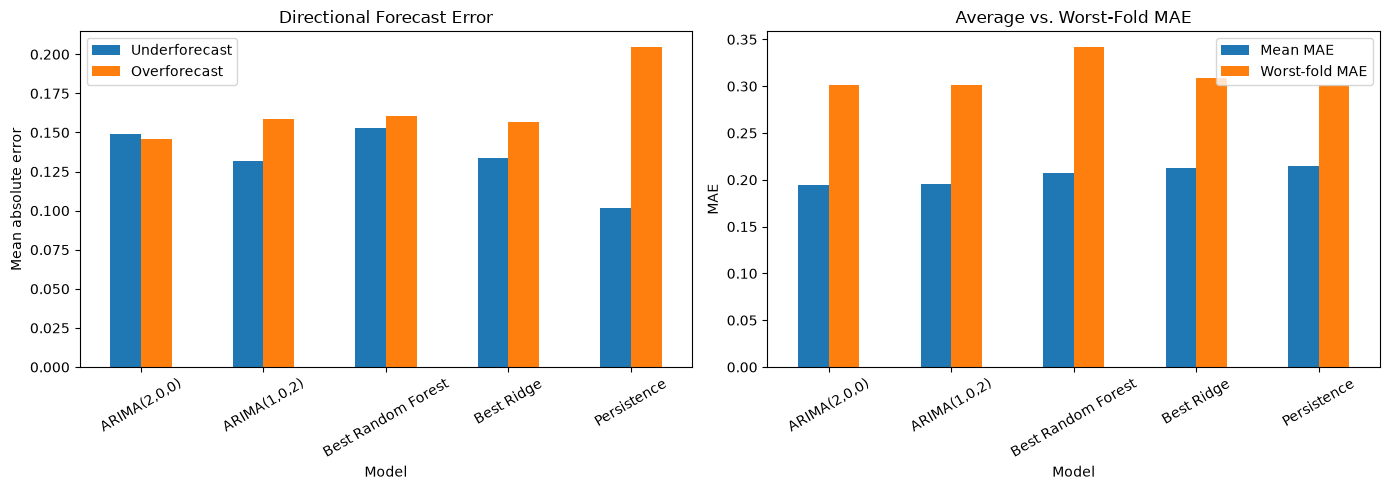

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_data = business_results.set_index("Model")

plot_data[
    ["Underforecast_MAE", "Overforecast_MAE"]
].plot(kind="bar", ax=axes[0])

axes[0].set_title("Directional Forecast Error")
axes[0].set_ylabel("Mean absolute error")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(["Underforecast", "Overforecast"])

plot_data[
    ["Mean_MAE", "Worst_Fold_MAE"]
].plot(kind="bar", ax=axes[1])

axes[1].set_title("Average vs. Worst-Fold MAE")
axes[1].set_ylabel("MAE")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(["Mean MAE", "Worst-fold MAE"])

plt.tight_layout()
plt.show()

## Fit the selected model

ARIMA(2, 0, 0) is used here because it had the lowest mean MAE and RMSE in rolling validation. The final fit uses the 110-point development window; the following holdout comparison is a retrospective diagnostic.

In [14]:
from statsmodels.tsa.arima.model import ARIMA

FINAL_ORDER = (2, 0, 0)

final_model = ARIMA(
    development_cpu,
    order=FINAL_ORDER,
).fit()

final_cpu_forecast = np.asarray(
    final_model.forecast(steps=HORIZON),
    dtype=float,
)

prediction_timestamps = holdout["timestamp"].to_numpy()

active_vm_count_forecast = int(
    development["active_vm_count"].iloc[-1]
)

predictions = pd.DataFrame({
    "timestamp": prediction_timestamps,
    "active_vm_count": active_vm_count_forecast,
    "aggregate_cpu_utilization": final_cpu_forecast,
})

expected_columns = [
    "timestamp",
    "active_vm_count",
    "aggregate_cpu_utilization",
]

assert predictions.columns.tolist() == expected_columns
assert len(predictions) == 24
assert predictions["timestamp"].is_monotonic_increasing
assert predictions["timestamp"].is_unique
assert predictions.notna().all().all()
assert np.isfinite(
    predictions["aggregate_cpu_utilization"].to_numpy()
).all()
assert (predictions["active_vm_count"] >= 0).all()
assert predictions["aggregate_cpu_utilization"].between(0, 100).all()

output_path = PROJECT_ROOT / "predictions.csv"
predictions.to_csv(output_path, index=False)

print(f"Selected model: ARIMA{FINAL_ORDER}")
print(f"Saved predictions to: {output_path}")
print(f"Rows: {len(predictions)}")
display(predictions.round(5))


Selected model: ARIMA(2, 0, 0)
Saved predictions to: c:\Users\User\projects\atomity\predictions.csv
Rows: 24


,timestamp,active_vm_count,aggregate_cpu_utilization
0,33000,10000,9.20465
1,33300,10000,9.23915
2,33600,10000,9.26724
3,33900,10000,9.29065
4,34200,10000,9.30998
5,34500,10000,9.32599
6,34800,10000,9.33924
7,35100,10000,9.35021
8,35400,10000,9.35928
9,35700,10000,9.36680


,MAE,RMSE,Mean_Bias,Max_Absolute_Error,Underforecast_Rate,Overforecast_Rate,Actual_Mean_CPU,Predicted_Mean_CPU,Actual_Min_CPU,Actual_Max_CPU
0,0.12437,0.14938,0.08654,0.27965,0.25,0.75,9.26899,9.35552,8.98361,9.63599


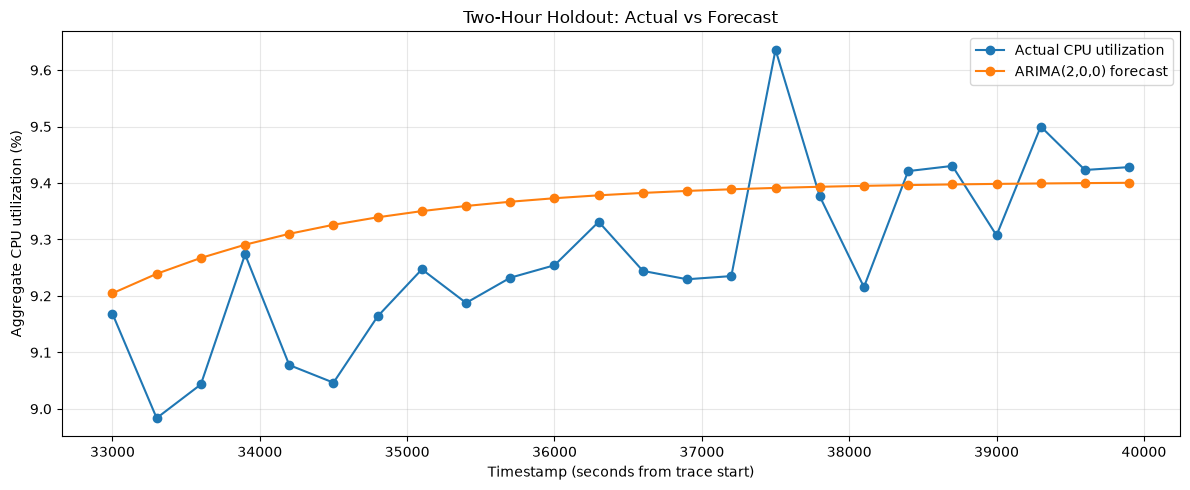

In [15]:
actual_cpu = holdout["aggregate_cpu_utilization"].to_numpy(dtype=float)
predicted_cpu = predictions["aggregate_cpu_utilization"].to_numpy(dtype=float)

errors = predicted_cpu - actual_cpu
absolute_errors = np.abs(errors)

holdout_metrics = pd.DataFrame([{
    "MAE": np.mean(absolute_errors),
    "RMSE": np.sqrt(np.mean(errors ** 2)),
    "Mean_Bias": np.mean(errors),
    "Max_Absolute_Error": np.max(absolute_errors),
    "Underforecast_Rate": np.mean(errors < 0),
    "Overforecast_Rate": np.mean(errors > 0),
    "Actual_Mean_CPU": np.mean(actual_cpu),
    "Predicted_Mean_CPU": np.mean(predicted_cpu),
    "Actual_Min_CPU": np.min(actual_cpu),
    "Actual_Max_CPU": np.max(actual_cpu),
}])

display(holdout_metrics.round(5))

plt.figure(figsize=(12, 5))
plt.plot(
    holdout["timestamp"],
    actual_cpu,
    marker="o",
    label="Actual CPU utilization",
)
plt.plot(
    predictions["timestamp"],
    predicted_cpu,
    marker="o",
    label="ARIMA(2,0,0) forecast",
)
plt.xlabel("Timestamp (seconds from trace start)")
plt.ylabel("Aggregate CPU utilization (%)")
plt.title("Two-Hour Holdout: Actual vs Forecast")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Retrospective holdout check

The final 24 actual values have already been inspected in this notebook. Keep this comparison descriptive; do not use it to claim untouched test performance or to change the selected model.

,Model,MAE,RMSE,Mean_Bias,Max_Absolute_Error,Underforecast_Rate,Overforecast_Rate
0,"ARIMA(1,0,2)",0.09781,0.12021,0.01968,0.31535,0.37500,0.62500
1,"ARIMA(2,0,0)",0.12437,0.14938,0.08654,0.27965,0.25000,0.75000
2,Persistence,0.14678,0.18479,-0.10443,0.47143,0.79167,0.20833


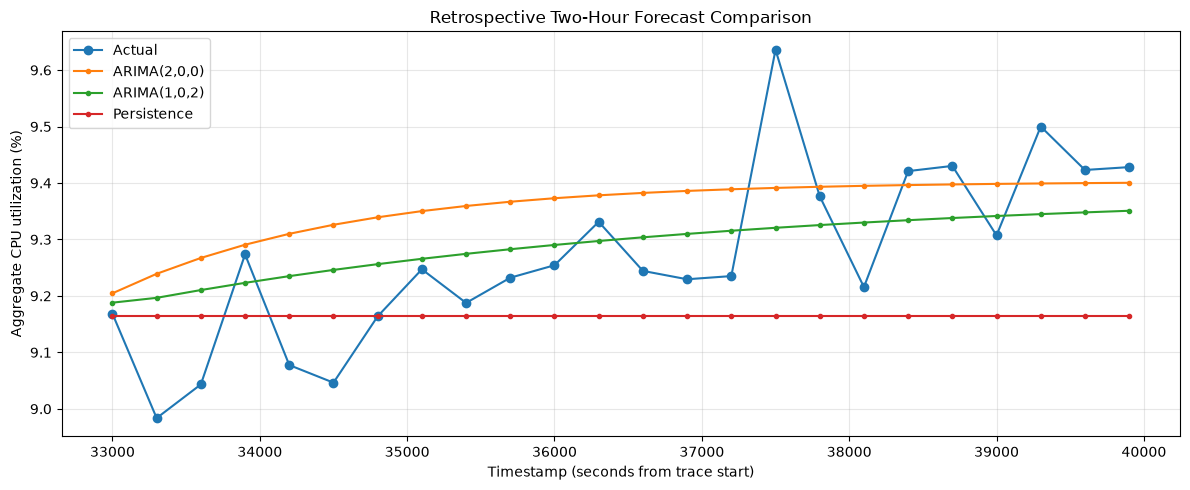

In [16]:
from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

actual = holdout["aggregate_cpu_utilization"].to_numpy(dtype=float)
history = development["aggregate_cpu_utilization"].to_numpy(dtype=float)

candidate_forecasts = {
    "ARIMA(2,0,0)": np.asarray(
        ARIMA(history, order=(2, 0, 0)).fit().forecast(steps=HORIZON),
        dtype=float,
    ),
    "ARIMA(1,0,2)": np.asarray(
        ARIMA(history, order=(1, 0, 2)).fit().forecast(steps=HORIZON),
        dtype=float,
    ),
    "Persistence": np.repeat(history[-1], HORIZON),
}

comparison_rows = []

for name, forecast in candidate_forecasts.items():
    errors = forecast - actual

    comparison_rows.append({
        "Model": name,
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "Mean_Bias": np.mean(errors),
        "Max_Absolute_Error": np.max(np.abs(errors)),
        "Underforecast_Rate": np.mean(errors < 0),
        "Overforecast_Rate": np.mean(errors > 0),
    })

holdout_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values(["MAE", "RMSE"])
    .reset_index(drop=True)
)

display(holdout_comparison.round(5))

plt.figure(figsize=(12, 5))

plt.plot(
    holdout["timestamp"], actual,
    marker="o", label="Actual",
)

for name, forecast in candidate_forecasts.items():
    plt.plot(
        holdout["timestamp"], forecast,
        marker=".", label=name,
    )

plt.xlabel("Timestamp (seconds from trace start)")
plt.ylabel("Aggregate CPU utilization (%)")
plt.title("Retrospective Two-Hour Forecast Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Final Findings and Recommendations

### Objective
Forecast aggregate CPU utilization over a two-hour horizon using Azure VM trace data and assess its usefulness for infrastructure planning.

### Model Selection
ARIMA(2,0,0) was selected based on rolling validation.

- **MAE:** 0.19483 percentage points
- **RMSE:** 0.22458 percentage points
- **Mean bias:** +0.01267 percentage points

ARIMA(1,0,2) achieved better retrospective holdout metrics, but the holdout had been inspected during exploration. Therefore, ARIMA(2,0,0) remains the validation-based selection.

### Holdout Results
ARIMA(2,0,0) achieved an MAE of 0.12437 and RMSE of 0.14938 percentage points. It captured the general upward trend but smoothed short-lived CPU spikes.

### Business Recommendations
- Use the model as a baseline for short-term workload forecasting.
- Account for underforecasting risk and maintain appropriate capacity headroom.
- Evaluate scaling policies using infrastructure costs, capacity limits, scaling lead times, and service-level objectives.
- Validate on longer traces before production deployment.

### Limitations
The dataset covers approximately 11.1 hours and provides aggregate CPU utilization, not physical server capacity. Consequently, it cannot establish optimal server provisioning or long-term workload patterns.

### Conclusion
The experiment demonstrates short-term predictability in aggregate CPU utilization. The selected model provides a useful forecasting baseline, but further operational validation is required before using its predictions for automated infrastructure decisions.

## Findings

Summarize what the rolling results support, where forecasts miss workload changes, and what an infrastructure team would still need before using the forecast operationally.

## Save the fitted model

The final cell serializes the fitted development-window ARIMA model for later inspection. This artifact is optional for generating `predictions.csv`, which the command-line pipeline can recreate from the raw data.

In [17]:
import pickle

model_path = PROJECT_ROOT / "model" / "arima_2_0_0.pkl"
model_path.parent.mkdir(parents=True, exist_ok=True)

with model_path.open("wb") as model_file:
    pickle.dump(final_model, model_file)

print(f"Saved fitted ARIMA{FINAL_ORDER} model to: {model_path}")

Saved fitted ARIMA(2, 0, 0) model to: c:\Users\User\projects\atomity\model\arima_2_0_0.pkl
